# 02 · EDA (Exploratory Data Analysis, ou análise exploratória de dados) com foco em negócio

Esta análise responde às quatro perguntas do item 3 do enunciado, com linguagem pensada para um(a) gerente de operações que não precisa conhecer estatística:

1. Quais fatores parecem mais críticos para a satisfação?
2. O que mais gera detratores?
3. Existe algum "ponto de ruptura" na experiência do cliente?
4. Que tipo de cliente tende a ter NPS (Net Promoter Score, ou índice de recomendação do cliente) mais alto ou mais baixo?

Cada seção segue o framework **Pergunta → Descoberta → Insight → Recomendação**, apresentado na Aula 4, e a escolha de cada gráfico segue o tipo de pergunta, como mostra a Aula 3: histogramas para distribuição, barras e boxplots para comparação, heatmap e correlação para relação, e barras empilhadas para composição.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy import stats

from src import config
from src.data_prep import load_raw_data, prepare_dataset, calculate_nps
from src.viz import set_style, save, summarize_by, bar_detractor_rate

set_style()
pd.set_option("display.float_format", "{:.2f}".format)

df = prepare_dataset(load_raw_data())
print(f"{len(df):,} pedidos | NPS geral: {calculate_nps(df['nps_score']):.0f} | "
      f"detratores: {df['is_detractor'].mean():.0%}")

2,500 pedidos | NPS geral: -80 | detratores: 84%


## 1. Distribuição das variáveis principais

**Pergunta:** como se distribuem a nota NPS e as variáveis de atraso e de reclamações?

Antes de cruzar variáveis, a Aula 2 recomenda observar como cada uma se distribui, porque a média sozinha pode esconder concentrações e assimetrias.

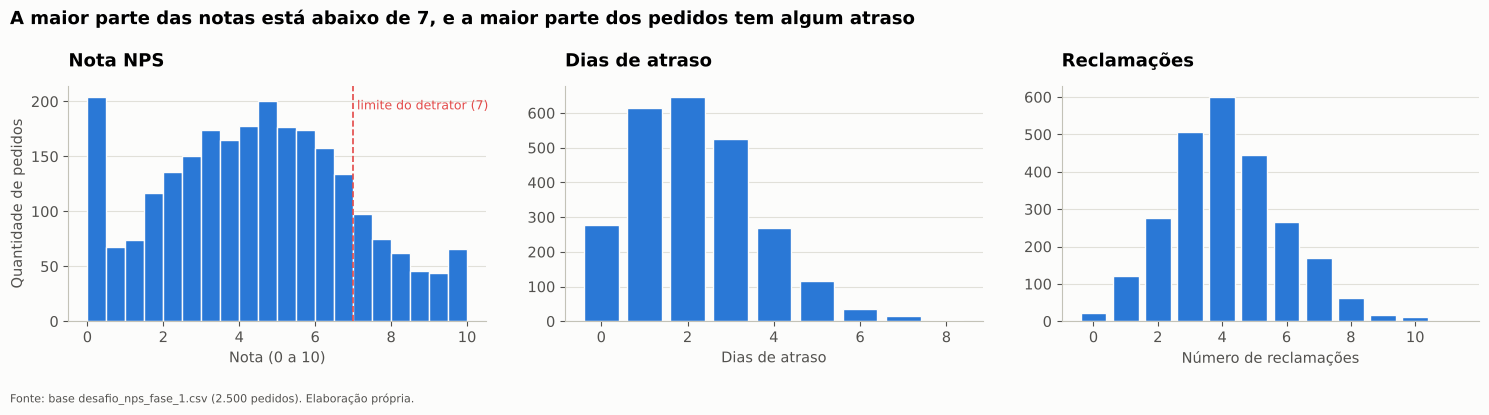

In [2]:
# Histograma da nota NPS e distribuição dos dias de atraso e das reclamações
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(df["nps_score"], bins=np.arange(0, 10.5, 0.5), color=config.COLOR_MAIN, edgecolor="#fcfcfb")
axes[0].axvline(7, color=config.COLOR_DETRACTOR, linestyle="--", linewidth=1.2)
axes[0].text(7.1, axes[0].get_ylim()[1] * 0.9, "limite do detrator (7)", color=config.COLOR_DETRACTOR, fontsize=9)
axes[0].set_title("Nota NPS"); axes[0].set_xlabel("Nota (0 a 10)"); axes[0].set_ylabel("Quantidade de pedidos")

delay_counts = df["delivery_delay_days"].value_counts().sort_index()
axes[1].bar(delay_counts.index, delay_counts.values, color=config.COLOR_MAIN, edgecolor="#fcfcfb")
axes[1].set_title("Dias de atraso"); axes[1].set_xlabel("Dias de atraso")

complaint_counts = df["complaints_count"].value_counts().sort_index()
axes[2].bar(complaint_counts.index, complaint_counts.values, color=config.COLOR_MAIN, edgecolor="#fcfcfb")
axes[2].set_title("Reclamações"); axes[2].set_xlabel("Número de reclamações")
fig.suptitle("A maior parte das notas está abaixo de 7, e a maior parte dos pedidos tem algum atraso",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
save(fig, "02a_distribuicoes")

In [3]:
# Medidas de posição: média e mediana de cada variável
df[["nps_score", "delivery_delay_days", "complaints_count", "customer_service_contacts"]].agg(["mean", "median"]).T

,mean,median
nps_score,4.38,4.40
delivery_delay_days,2.19,2.00
complaints_count,4.15,4.00
customer_service_contacts,1.52,1.00


**Descoberta:** a nota NPS tem média de 4,4 e se concentra abaixo de 7, enquanto apenas 11% dos pedidos chegaram sem atraso (277 de 2.500), e a mediana é de 2 dias de atraso e de 4 reclamações por cliente.

**Insight:** a insatisfação não está concentrada em um pequeno grupo de casos extremos, mas espalhada pela maior parte da base, o que sugere um problema estrutural da operação, e não pontual.

## 2. Quais fatores parecem mais críticos?

**Pergunta:** quais variáveis da operação estão relacionadas à nota do NPS?

Para responder, usamos a **correlação de Spearman**, que indica se uma variável aumenta quando a outra aumenta ou diminui, sem exigir uma relação em linha reta. Ela varia de -1 a +1, e quanto mais distante de zero, mais forte é a relação.

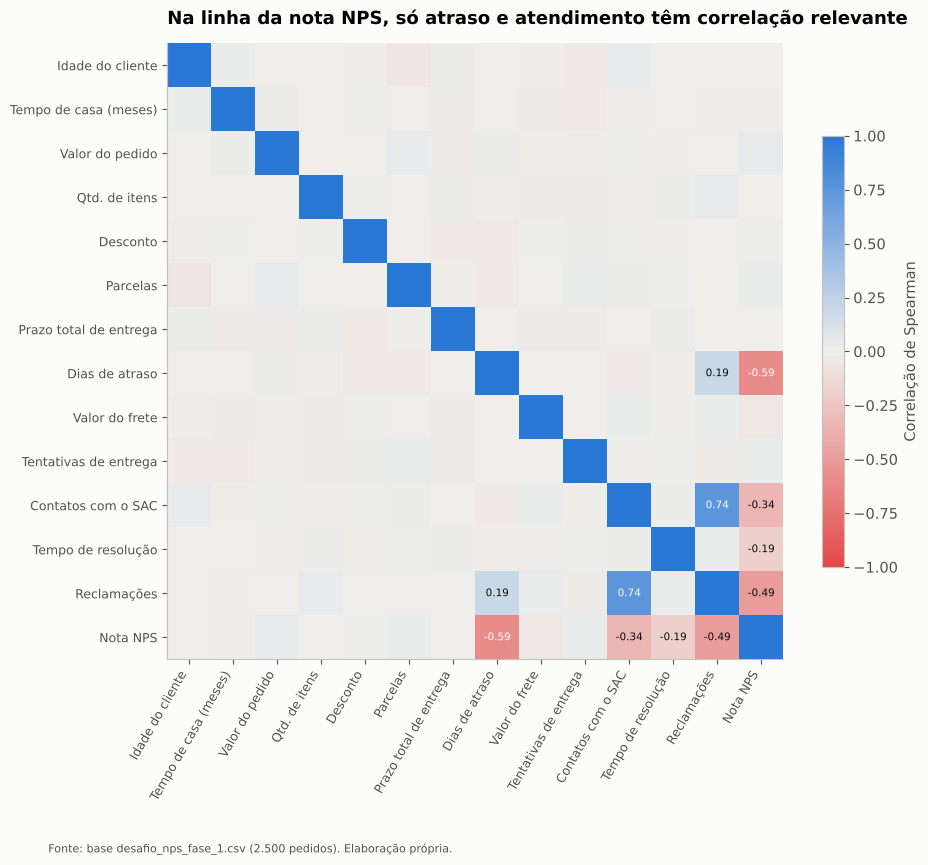

In [4]:
# Heatmap de correlação entre a nota NPS e as variáveis operacionais
operational = config.NUMERIC_FEATURES
corr_matrix = df[operational + ["nps_score"]].corr(method="spearman")
labels = [config.FRIENDLY_NAMES[c] for c in corr_matrix.columns]

cmap = LinearSegmentedColormap.from_list("div", [config.COLOR_DETRACTOR, "#f0efec", config.COLOR_PROMOTER])
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=9)
ax.set_yticks(range(len(labels)), labels, fontsize=9)
for i in range(len(labels)):
    for j in range(len(labels)):
        value = corr_matrix.values[i, j]
        if abs(value) >= 0.15 and i != j:
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7.5,
                    color="#fcfcfb" if abs(value) > 0.5 else config.COLOR_TEXT)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Correlação de Spearman")
ax.set_title("Na linha da nota NPS, só atraso e atendimento têm correlação relevante")
save(fig, "02b_heatmap_correlacao", source_y=-0.12)

In [5]:
# Correlação de cada variável operacional com a nota NPS, em ordem
corr = corr_matrix["nps_score"].drop("nps_score").sort_values()
corr.rename(index=config.FRIENDLY_NAMES).to_frame("correlação com a nota NPS")

,correlação com a nota NPS
Dias de atraso,-0.59
Reclamações,-0.49
Contatos com o SAC,-0.34
Tempo de resolução,-0.19
Valor do frete,-0.04
Tempo de casa (meses),-0.01
Idade do cliente,-0.01
Prazo total de entrega,0.00
Qtd. de itens,0.01
Desconto,0.01


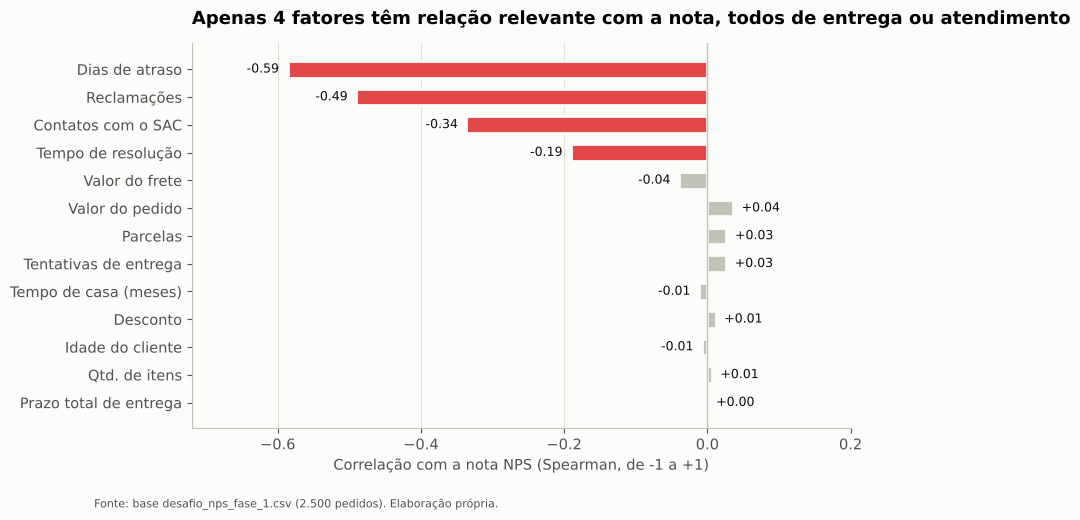

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 5))
ordered = corr.reindex(corr.abs().sort_values().index)
colors = [config.COLOR_DETRACTOR if abs(v) >= 0.15 else config.COLOR_CONTEXT for v in ordered]
ax.barh([config.FRIENDLY_NAMES[i] for i in ordered.index], ordered.values, color=colors, height=0.6,
        edgecolor="#fcfcfb", linewidth=2)
for y, v in enumerate(ordered.values):
    ax.text(v + (0.012 if v >= 0 else -0.012), y, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color=config.COLOR_TEXT)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlim(-0.72, 0.2); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlabel("Correlação com a nota NPS (Spearman, de -1 a +1)")
ax.set_title("Apenas 4 fatores têm relação relevante com a nota, todos de entrega ou atendimento")
save(fig, "02_fatores_correlacao")

**Descoberta:** quatro variáveis se destacam, todas com relação negativa, ou seja, quanto maior o valor, menor a nota:

1. **Dias de atraso** (-0,59), o fator mais forte;
2. **Reclamações** (-0,49);
3. **Contatos com o SAC** (Serviço de Atendimento ao Consumidor) (-0,34);
4. **Tempo de resolução** (-0,19).

As demais variáveis, como valor do pedido, frete, desconto, parcelas, idade e tempo de relacionamento, têm correlação próxima de zero.

**Insight:** o NPS desta empresa não depende de preço nem do perfil do cliente, e sim do cumprimento da promessa de entrega e da resolução dos problemas. As hipóteses H1, H2 e H3 são confirmadas, enquanto H4 e H5 são refutadas.

> Como alertam as Aulas 2 e 3, correlação não significa causalidade, e esses resultados indicam associações que orientam as hipóteses e as ações, mas que precisam ser validadas.

## 3. Ponto de ruptura: o atraso na entrega

**Pergunta:** a partir de quantos dias de atraso a satisfação cai de forma acentuada?

In [7]:
delay_summary = summarize_by(df, "faixa_atraso")
delay_summary

,pedidos,nota_media,pct_detratores,pct_promotores,nps
faixa_atraso,,,,,
Sem atraso,277,6.90,51.60,18.10,-33.60
1 dia,615,5.50,74.00,7.20,-66.80
2 dias,646,4.60,87.90,2.00,-85.90
3 dias,525,3.40,96.80,0.60,-96.20
4+ dias,437,2.00,99.50,0.00,-99.50


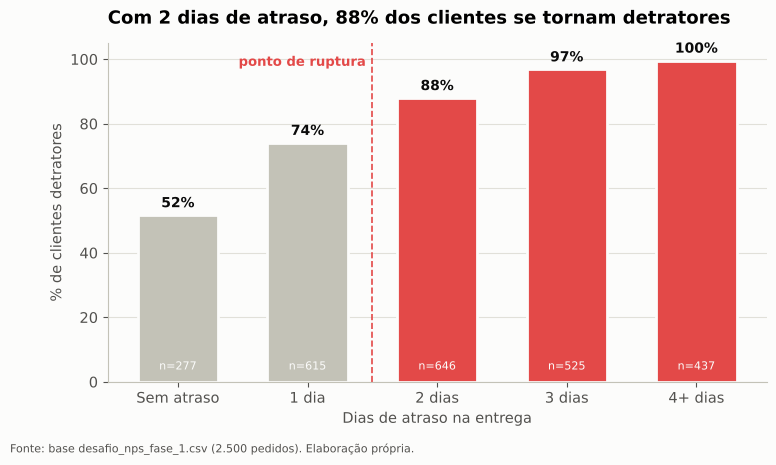

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
bar_detractor_rate(delay_summary, title="Com 2 dias de atraso, 88% dos clientes se tornam detratores",
                   xlabel="Dias de atraso na entrega", highlight_from="2 dias", ax=ax)
ax.axvline(1.5, color=config.COLOR_DETRACTOR, linestyle="--", linewidth=1.2)
ax.text(1.45, 99, "ponto de ruptura", ha="right", va="center", fontsize=9.5, color=config.COLOR_DETRACTOR, fontweight="bold")
save(fig, "03_ruptura_atraso")

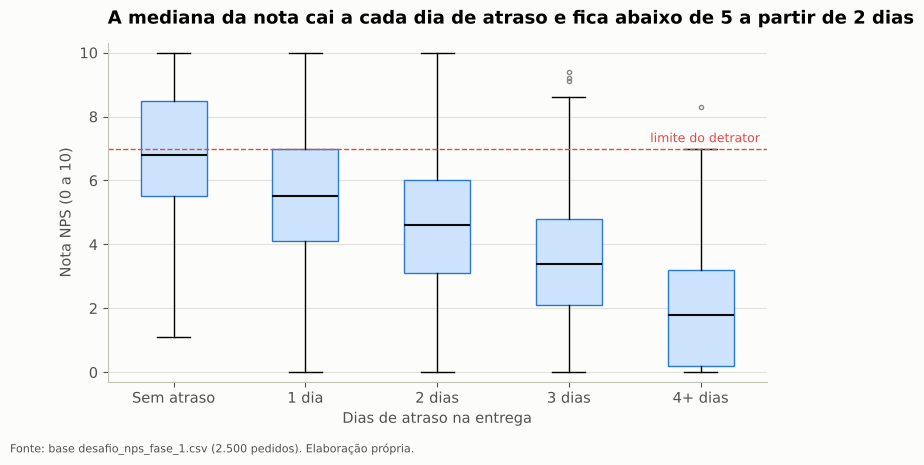

In [9]:
# Boxplot da nota NPS por faixa de atraso (comparação da distribuição entre grupos)
groups = [g["nps_score"].values for _, g in df.groupby("faixa_atraso", observed=True)]
group_labels = [str(k) for k in df["faixa_atraso"].cat.categories]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.boxplot(groups, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", color=config.COLOR_MAIN),
           medianprops=dict(color=config.COLOR_TEXT, linewidth=1.5),
           flierprops=dict(markeredgecolor="#898781", markersize=3))
ax.set_xticks(range(1, len(group_labels) + 1), group_labels)
ax.axhline(7, color=config.COLOR_DETRACTOR, linestyle="--", linewidth=1)
ax.text(5.45, 7.2, "limite do detrator", color=config.COLOR_DETRACTOR, fontsize=9, ha="right")
ax.set_ylim(-0.3, 10.3); ax.set_xlabel("Dias de atraso na entrega"); ax.set_ylabel("Nota NPS (0 a 10)")
ax.set_title("A mediana da nota cai a cada dia de atraso e fica abaixo de 5 a partir de 2 dias")
save(fig, "03b_boxplot_atraso")

In [10]:
# Variação média da nota a cada dia de atraso (inclinação de uma reta ajustada)
by_day = df.groupby("delivery_delay_days")["nps_score"].agg(["size", "mean"]).rename(
    columns={"size": "pedidos", "mean": "nota_media"})
slope = np.polyfit(df["delivery_delay_days"], df["nps_score"], 1)[0]
print(f"Cada dia de atraso reduz a nota média em cerca de {abs(slope):.1f} ponto (escala de 0 a 10)")
by_day.T

Cada dia de atraso reduz a nota média em cerca de 1.0 ponto (escala de 0 a 10)


delivery_delay_days,0,1,2,3,4,5,6,7,8
pedidos,277.00,615.00,646.00,525.00,270.00,116.00,34.00,14.00,3.00
nota_media,6.86,5.55,4.58,3.44,2.44,1.48,1.10,0.29,0.00


**Descoberta:**

- Sem atraso, a nota média é de 6,9 e o NPS é de -34, que ainda é um resultado ruim, mas é o melhor cenário encontrado na base.
- Com 1 dia de atraso, 74% dos clientes são detratores.
- Com 2 dias de atraso, os detratores chegam a 88% e os promotores praticamente desaparecem, caindo para 2%.
- Com 4 dias ou mais, de 99% a 100% dos clientes são detratores.
- Cada dia de atraso reduz a nota média em cerca de 1 ponto.

**Insight:** o ponto de ruptura está em **2 dias de atraso**, a partir do qual a recuperação do cliente se torna muito difícil, e 64% dos pedidos da base já estão nessa faixa.

**Recomendação:** tratar o atraso de 2 dias ou mais como alerta operacional, avisando o cliente antes do segundo dia e oferecendo compensação de forma automática.

### Prazo total ou atraso?

**Pergunta:** a demora da entrega também gera insatisfação, ou o que pesa é apenas o atraso em relação ao prometido?

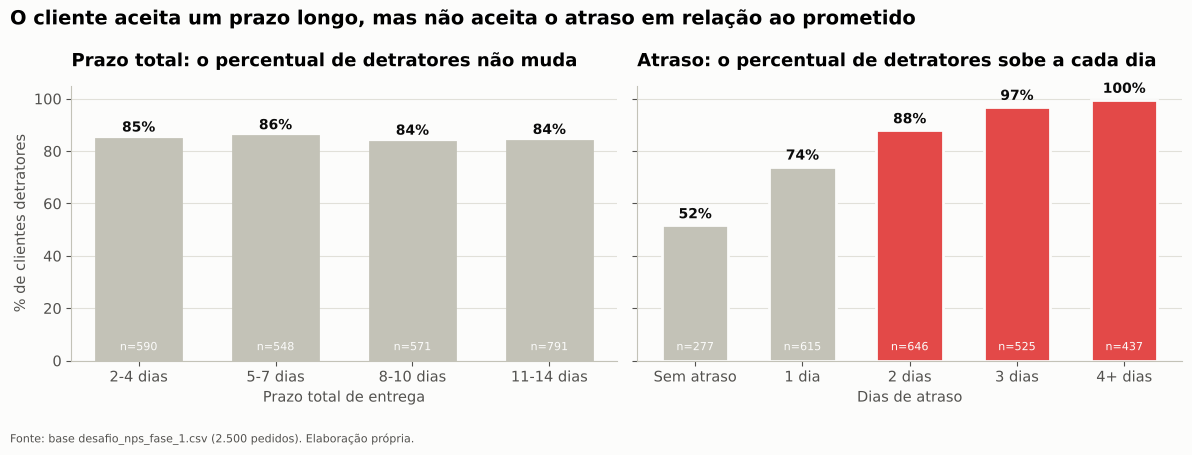

,pedidos,nota_media,pct_detratores,pct_promotores,nps
faixa_prazo_total,,,,,
2-4 dias,590,4.30,84.70,4.60,-80.20
5-7 dias,548,4.50,85.60,4.20,-81.40
8-10 dias,571,4.50,83.50,4.90,-78.60
11-14 dias,791,4.30,83.80,4.00,-79.80


In [11]:
df["faixa_prazo_total"] = pd.cut(df["delivery_time_days"], bins=[0, 4, 7, 10, 14],
                                 labels=["2-4 dias", "5-7 dias", "8-10 dias", "11-14 dias"])
deadline_summary = summarize_by(df, "faixa_prazo_total")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
bar_detractor_rate(deadline_summary, title="Prazo total: o percentual de detratores não muda", xlabel="Prazo total de entrega", ax=axes[0])
for bar in axes[0].patches:
    bar.set_color(config.COLOR_CONTEXT)
bar_detractor_rate(delay_summary, title="Atraso: o percentual de detratores sobe a cada dia", xlabel="Dias de atraso", highlight_from="2 dias", ax=axes[1])
axes[1].set_ylabel("")
fig.suptitle("O cliente aceita um prazo longo, mas não aceita o atraso em relação ao prometido", x=0.01, ha="left", fontweight="bold", fontsize=14)
plt.tight_layout()
save(fig, "04_prazo_vs_atraso")
deadline_summary

**Descoberta:** o percentual de detratores fica em torno de 84% em todas as faixas de prazo total, de 2 a 14 dias, enquanto sobe de forma contínua com os dias de atraso.

**Insight:** este é um achado do tipo **quebra de expectativa**, um dos padrões narrativos da Aula 4, porque seria natural supor que entregas longas gerassem insatisfação. Enquanto uma entrega de 14 dias que chega na data combinada tem o mesmo NPS que uma de 3 dias, o atraso em relação ao prometido derruba a nota.

**Recomendação:** comunicar um prazo realista, que a operação consiga cumprir, recalibrando o prazo exibido no checkout (etapa final da compra) com base no histórico de cada rota.

## 4. Atendimento: reclamações, contatos e tempo de resolução

**Pergunta:** como o volume de reclamações, de contatos com o SAC e o tempo de resolução se relacionam com a detração?

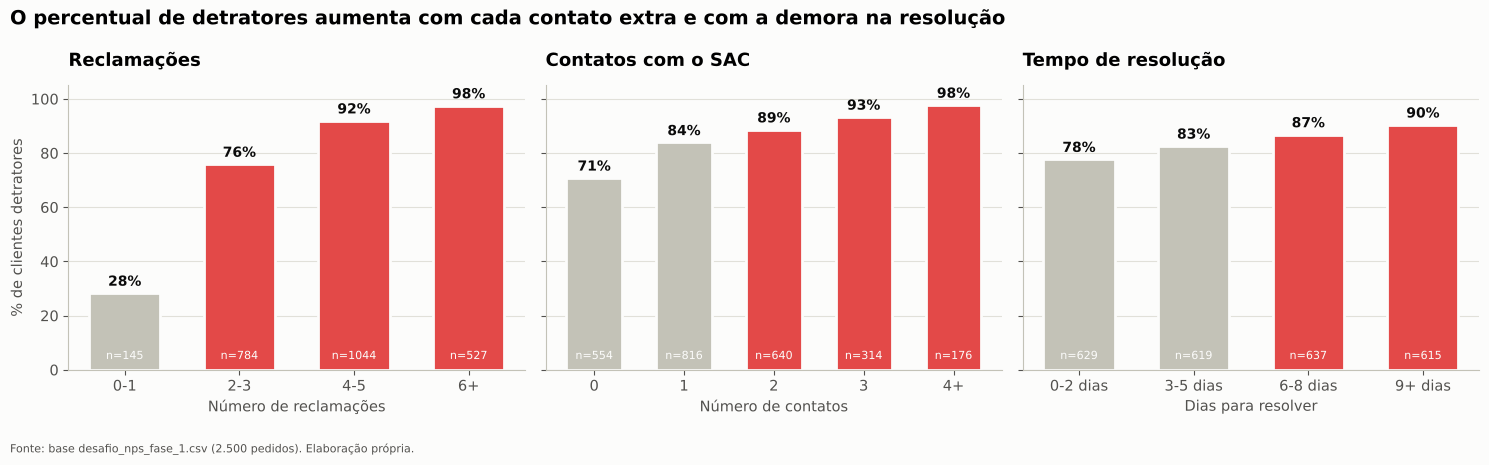

In [12]:
complaints_summary = summarize_by(df, "faixa_reclamacoes")
contacts_summary = summarize_by(df, "faixa_contatos_sac")
resolution_summary = summarize_by(df, "faixa_resolucao")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=True)
bar_detractor_rate(complaints_summary, "Reclamações", "Número de reclamações", highlight_from="2-3", ax=axes[0])
bar_detractor_rate(contacts_summary, "Contatos com o SAC", "Número de contatos", highlight_from="2", ax=axes[1])
bar_detractor_rate(resolution_summary, "Tempo de resolução", "Dias para resolver", highlight_from="6-8 dias", ax=axes[2])
for ax in axes[1:]:
    ax.set_ylabel("")
fig.suptitle("O percentual de detratores aumenta com cada contato extra e com a demora na resolução",
             x=0.01, ha="left", fontweight="bold", fontsize=14)
plt.tight_layout()
save(fig, "05_atendimento")

In [13]:
pd.concat({"Reclamações": complaints_summary, "Contatos SAC": contacts_summary,
           "Tempo de resolução": resolution_summary})[["pedidos", "pct_detratores", "nps"]]

**Descoberta:**

- Com 0 ou 1 reclamação, 28% dos clientes são detratores, e com 2 ou 3 reclamações esse percentual sobe para 76%.
- Os clientes que não precisaram falar com o SAC têm NPS de -60, que cai para -86 com 2 contatos e para -97 com 4 contatos ou mais.
- A resolução em até 2 dias está associada a NPS de -70, contra -89 quando leva 9 dias ou mais.

**Insight:** cada contato adicional com o SAC indica um problema que não foi resolvido na primeira vez, e a demora na resolução agrava a insatisfação.

**Recomendação:**

- Adotar a meta de FCR (First Contact Resolution, ou resolução no primeiro contato).
- Definir um SLA (Service Level Agreement, ou acordo de nível de serviço) de resolução de até 2 dias.
- Encaminhar o cliente para uma fila prioritária a partir do segundo contato, com autonomia para oferecer compensação.

## 5. Efeito combinado: quando os problemas se somam

**Pergunta:** o que acontece com a nota quando o cliente enfrenta mais de um problema?

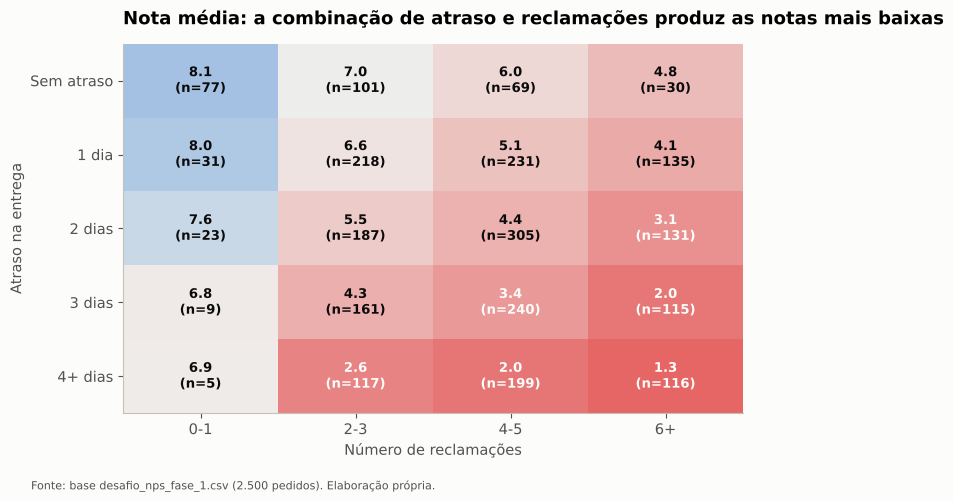

In [14]:
# Nota média por combinação de faixa de atraso e faixa de reclamações
heat = df.pivot_table(index="faixa_atraso", columns="faixa_reclamacoes",
                      values="nps_score", aggfunc="mean", observed=True)
counts = df.pivot_table(index="faixa_atraso", columns="faixa_reclamacoes",
                        values="nps_score", aggfunc="size", observed=True)

# Escala divergente: vermelho para nota baixa, cinza para nota 7 (limite do detrator) e azul para nota alta
cmap = LinearSegmentedColormap.from_list("nps", [config.COLOR_DETRACTOR, "#f0efec", config.COLOR_PROMOTER])
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.imshow(heat.values, cmap=cmap, norm=TwoSlopeNorm(vmin=0, vcenter=7, vmax=10), aspect="auto")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat.iloc[i, j]:.1f}\n(n={counts.iloc[i, j]})", ha="center", va="center", fontsize=9.5,
                color=config.COLOR_TEXT if heat.iloc[i, j] > 3.5 else "#fcfcfb", fontweight="bold")
ax.set_xticks(range(heat.shape[1]), heat.columns); ax.set_yticks(range(heat.shape[0]), heat.index)
ax.set_xlabel("Número de reclamações"); ax.set_ylabel("Atraso na entrega"); ax.grid(False)
ax.set_title("Nota média: a combinação de atraso e reclamações produz as notas mais baixas")
save(fig, "06_mapa_atraso_reclamacoes")

In [15]:
# Quantidade de fatores críticos em cada pedido
# Fatores críticos, definidos a partir dos pontos de ruptura encontrados acima:
#   atraso >= 2 dias | reclamações >= 4 | contatos com o SAC >= 2
df["fatores_criticos"] = ((df["delivery_delay_days"] >= 2).astype(int)
                          + (df["complaints_count"] >= 4).astype(int)
                          + (df["customer_service_contacts"] >= 2).astype(int))
critical_summary = summarize_by(df, "fatores_criticos")
critical_summary["pct_pedidos"] = 100 * critical_summary["pedidos"] / len(df)
critical_summary

,pedidos,nota_media,pct_detratores,pct_promotores,nps,pct_pedidos
fatores_criticos,,,,,,
0,357,7.10,47.90,20.20,-27.70,14.28
1,680,5.00,80.60,3.70,-76.90,27.20
2,760,4.10,92.40,1.30,-91.10,30.40
3,703,2.70,97.90,0.40,-97.40,28.12


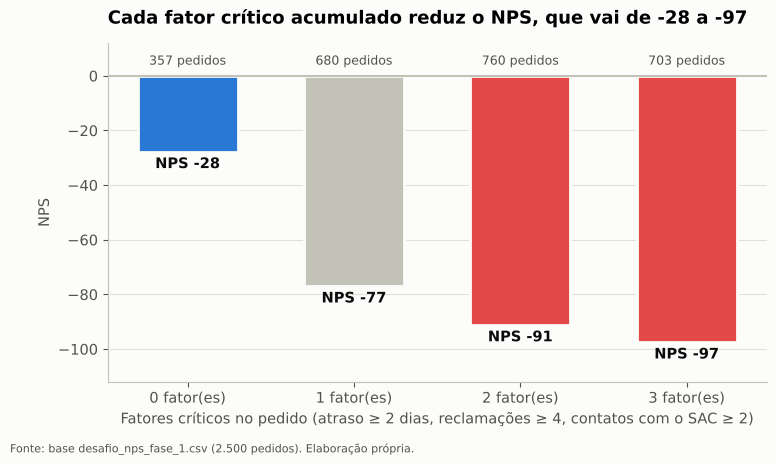

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
values = critical_summary["nps"]
colors = [config.COLOR_PROMOTER, config.COLOR_CONTEXT, config.COLOR_DETRACTOR, config.COLOR_DETRACTOR]
bars = ax.bar([f"{i} fator(es)" for i in values.index], values, color=colors, width=0.6, edgecolor="#fcfcfb", linewidth=2)
for bar, v, n in zip(bars, values, critical_summary["pedidos"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v - 2, f"NPS {v:.0f}", ha="center", va="top", fontweight="bold",
            color=config.COLOR_TEXT)
    ax.text(bar.get_x() + bar.get_width() / 2, 3, f"{n} pedidos", ha="center", va="bottom", fontsize=9,
            color=config.COLOR_TEXT_SECONDARY)
ax.axhline(0, color="#c3c2b7"); ax.set_ylim(-112, 12)
ax.set_ylabel("NPS")
ax.set_xlabel("Fatores críticos no pedido (atraso ≥ 2 dias, reclamações ≥ 4, contatos com o SAC ≥ 2)")
ax.set_title("Cada fator crítico acumulado reduz o NPS, que vai de -28 a -97")
save(fig, "07_fatores_acumulados")

**Descoberta:**

- Os pedidos sem nenhum fator crítico, que são 14% da base, têm nota média de 7,1, NPS de -28 e 20% de promotores.
- Com 1 fator crítico, o NPS cai para -77.
- Com os 3 fatores, o NPS chega a -97, com 98% de detratores.
- Os pedidos sem atraso e com até 1 reclamação formam o único grupo com NPS positivo (+9).

**Insight:** os problemas se somam, e evitar o **primeiro** problema é o que tem maior efeito, porque a passagem de nenhum para 1 fator crítico reduz o NPS em 49 pontos.

## 6. O que mais gera detratores?

**Pergunta:** que parcela dos detratores passou por cada um dos fatores críticos?

In [17]:
detractors = df[df["is_detractor"] == 1]
causes = pd.Series({
    "Atraso ≥ 2 dias": (detractors["delivery_delay_days"] >= 2).mean(),
    "Reclamações ≥ 4": (detractors["complaints_count"] >= 4).mean(),
    "Contatos SAC ≥ 2": (detractors["customer_service_contacts"] >= 2).mean(),
    "Resolução ≥ 6 dias": (detractors["resolution_time_days"] >= 6).mean(),
    "Pelo menos 1 fator crítico": (detractors["fatores_criticos"] >= 1).mean(),
}).mul(100).round(1)
causes.to_frame("% dos detratores com o fator")

,% dos detratores com o fator
Atraso ≥ 2 dias,71.60
Reclamações ≥ 4,69.80
Contatos SAC ≥ 2,48.90
Resolução ≥ 6 dias,52.60
Pelo menos 1 fator crítico,91.90


**Descoberta:** 92% dos detratores passaram por pelo menos um fator crítico, o atraso de 2 dias ou mais aparece em 72% deles e as 4 reclamações ou mais, em 70%.

**Insight:** a maior parte da detração está associada a falhas da operação que podem ser evitadas, como o atraso na entrega e os problemas não resolvidos no atendimento.

## 7. Que tipo de cliente tem NPS mais alto ou mais baixo?

**Pergunta:** o NPS varia conforme o perfil do cliente?

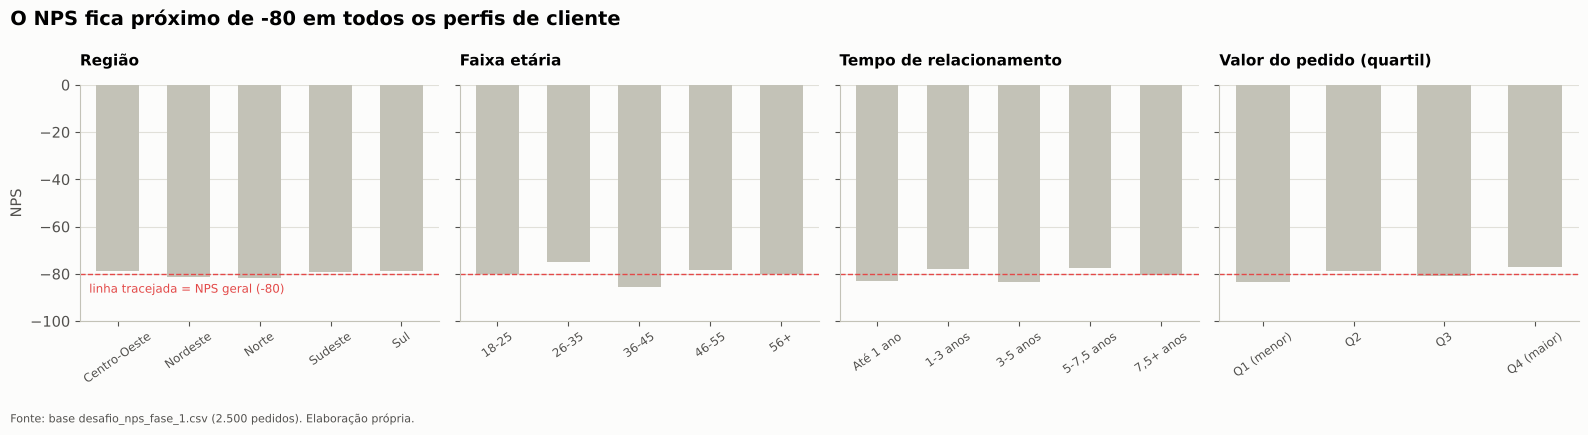

In [18]:
profile_cols = {"customer_region": "Região", "faixa_idade": "Faixa etária",
                "faixa_tempo_casa": "Tempo de relacionamento", "faixa_valor_pedido": "Valor do pedido (quartil)"}
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, (col, label) in zip(axes, profile_cols.items()):
    summary = summarize_by(df, col)
    ax.bar([str(i) for i in summary.index], summary["nps"], color=config.COLOR_CONTEXT, width=0.6)
    ax.axhline(calculate_nps(df["nps_score"]), color=config.COLOR_DETRACTOR, linestyle="--", linewidth=1)
    ax.set_title(label, fontsize=11); ax.tick_params(axis="x", rotation=35, labelsize=8.5)
    ax.set_ylim(-100, 0)
axes[0].set_ylabel("NPS")
axes[0].text(-0.4, calculate_nps(df["nps_score"]) - 8, "linha tracejada = NPS geral (-80)", color=config.COLOR_DETRACTOR, fontsize=8.5, ha="left")
fig.suptitle("O NPS fica próximo de -80 em todos os perfis de cliente",
             x=0.01, ha="left", fontweight="bold", fontsize=14)
plt.tight_layout()
save(fig, "08_perfil_cliente")

In [19]:
# Teste de Kruskal-Wallis: as notas diferem entre os grupos?
# p-valor menor que 0,05 indica diferença real; p-valor alto indica que a diferença pode ser acaso
tests = {}
for col, label in {**profile_cols, "faixa_atraso": "Atraso (para comparação)"}.items():
    groups = [g["nps_score"].values for _, g in df.groupby(col, observed=True)]
    tests[label] = stats.kruskal(*groups).pvalue
pd.Series(tests, name="p-valor").map("{:.3g}".format).to_frame()

,p-valor
Região,0.497
Faixa etária,0.107
Tempo de relacionamento,0.315
Valor do pedido (quartil),0.0611
Atraso (para comparação),1.14e-184


In [20]:
# Médias dos fatores críticos por região, para verificar se alguma região é atendida de forma diferente
df.groupby("customer_region")[["delivery_delay_days", "complaints_count", "customer_service_contacts"]].mean().round(2)

,delivery_delay_days,complaints_count,customer_service_contacts
customer_region,,,
Centro-Oeste,2.22,4.18,1.59
Nordeste,2.19,4.16,1.51
Norte,2.14,4.11,1.46
Sudeste,2.22,4.24,1.49
Sul,2.17,4.06,1.55


Para testar se as diferenças entre perfis são reais, usamos o teste de Kruskal-Wallis, que verifica se vários grupos têm notas de fato diferentes. O resultado é o p-valor, que indica a probabilidade de a diferença observada ser fruto do acaso, e valores abaixo de 0,05 indicam diferença real.

**Descoberta:**

- **Região:** o NPS varia entre -82, no Norte, e -79, no Sul e no Centro-Oeste, sem significância estatística (p = 0,50), e o atraso médio também é parecido entre as regiões.
- **Faixa etária:** a faixa de 26 a 35 anos tem NPS um pouco melhor (-75) e a de 36 a 45 anos, um pouco pior (-86), também sem significância estatística (p = 0,11).
- **Tempo de relacionamento e valor do pedido:** as variações são pequenas, e os pedidos do quartil de maior valor (Q4) têm NPS levemente melhor (-77 contra -84).
- Para comparação, o atraso apresenta p-valor praticamente igual a zero, o que confirma uma diferença real entre as faixas.

**Insight:** não existe um perfil demográfico de detrator. O que diferencia o promotor do detrator é a experiência que ele teve, e o cliente com NPS mais alto é aquele que recebeu o pedido no prazo e não precisou reclamar.

**Recomendação:** segmentar as ações pela situação do pedido, como atraso ou chamado aberto, e não pelo perfil demográfico do cliente.

## 8. Por que isso importa: NPS e recompra

**Pergunta:** a categoria de NPS está associada à recompra?

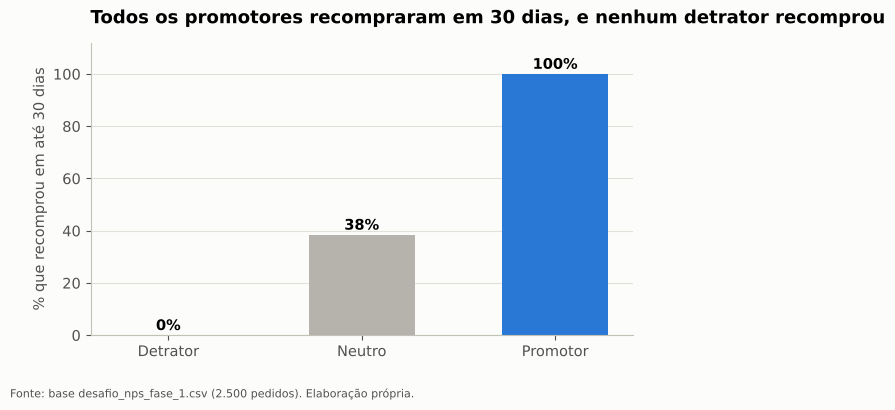

,% recompra em 30 dias
nps_category,
Detrator,0.00
Neutro,38.40
Promotor,100.00


In [21]:
repurchase = df.groupby("nps_category")["repeat_purchase_30d"].mean().reindex(["Detrator", "Neutro", "Promotor"]) * 100

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(repurchase.index, repurchase.values, color=[config.CATEGORY_COLORS[c] for c in repurchase.index], width=0.55)
for bar, v in zip(bars, repurchase.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 2, f"{v:.0f}%", ha="center", fontweight="bold")
ax.set_ylim(0, 112); ax.set_ylabel("% que recomprou em até 30 dias")
ax.set_title("Todos os promotores recompraram em 30 dias, e nenhum detrator recomprou")
save(fig, "09_recompra")
repurchase.round(1).to_frame("% recompra em 30 dias")

**Descoberta:** 100% dos promotores recompraram em até 30 dias, contra 38% dos neutros e nenhum detrator.

**Insight:** converter detratores em neutros ou promotores tem efeito direto sobre a receita de recompra.

> Uma relação tão regular, de 0% e 100%, é incomum em dados reais e sugere que a base pode ser simulada ou que a recompra foi registrada junto com o NPS. Por isso, essa variável não entra no modelo, como explicado no notebook 01.

---

## Registro das descobertas e hipóteses

A Aula 2 recomenda registrar as descobertas no formato Observação → Evidência → Hipótese → Próximos passos, para que qualquer pessoa consiga acompanhar o raciocínio e continuar o trabalho.

| Observação | Evidência | Hipótese associada | Próximos passos |
|---|---|---|---|
| O atraso é o fator mais associado à detração | Correlação de -0,59; 88% de detratores com 2 dias de atraso | Quebrar a promessa de entrega é o principal motivo de insatisfação | Testar um alerta de atraso em uma região piloto |
| O prazo total não altera o NPS | Cerca de 84% de detratores em todas as faixas de prazo | O cliente avalia o cumprimento da promessa, e não a rapidez | Confirmar como o prazo exibido no checkout é calculado |
| Reclamações e contatos com o SAC elevam a detração | 28% de detratores com 0-1 reclamação contra 76% com 2-3; NPS de -60 sem contato contra -97 com 4 ou mais | Problemas não resolvidos no primeiro contato agravam a insatisfação | Medir o FCR e classificar o motivo das reclamações |
| Os problemas se somam | NPS de -28 sem fator crítico e de -97 com 3 fatores | Evitar o primeiro problema é a ação de maior efeito | Usar a contagem de fatores críticos no acompanhamento de risco |
| O perfil do cliente não altera o NPS | p-valores de 0,06 a 0,50 nos testes de perfil | A satisfação depende da experiência, e não da demografia | Segmentar as ações pela situação do pedido |

### Resultado das hipóteses iniciais

| # | Hipótese | Resultado |
|---|---|---|
| H1 | Atraso na entrega derruba o NPS | Confirmada, sendo o fator mais forte |
| H2 | Muitos contatos com o SAC e resolução lenta derrubam o NPS | Confirmada |
| H3 | Mais reclamações levam a mais detratores | Confirmada |
| H4 | Frete caro e pouco desconto reduzem a satisfação | Refutada, com relação praticamente nula |
| H5 | O perfil do cliente muda o NPS | Refutada, sem significância estatística |

### Resumo das respostas ao enunciado

| Pergunta | Resposta |
|---|---|
| **Fatores mais críticos** | Atraso na entrega, seguido de reclamações, contatos com o SAC e tempo de resolução |
| **O que mais gera detratores** | O atraso de 2 dias ou mais, presente em 72% dos detratores; 92% dos detratores passaram por pelo menos 1 fator crítico |
| **Ponto de ruptura** | **2 dias de atraso**, com 88% de detratores, e **2 reclamações**, quando os detratores passam de 28% para 76% |
| **Perfil com NPS mais alto ou mais baixo** | Não há perfil demográfico; o NPS é mais alto quando o pedido chega no prazo e o cliente não precisa reclamar |
| **Fatores sem efeito relevante** | Prazo total, frete, desconto, parcelas, valor do pedido, região, idade e tempo de relacionamento |

### Recomendações

1. **Logística:** criar um alerta automático para pedidos próximos de 1 dia de atraso e recalibrar o prazo prometido por rota.
2. **Atendimento:** adotar a meta de FCR, fila prioritária a partir do segundo contato e SLA de resolução de até 2 dias.
3. **Experiência do Cliente:** fazer contato proativo e oferecer compensação, como cupom ou frete grátis, aos pedidos atrasados antes da pesquisa.
4. **Dados:** usar o modelo do notebook 03 para calcular o risco de cada pedido e aprofundar a análise com dados de transportadora, categoria de produto e motivo das reclamações.

Próximo notebook: `03_modelo_preditivo.ipynb`

## Glossário

| Termo | Significado |
|---|---|
| Boxplot | Gráfico que mostra mediana, quartis e valores extremos de uma variável. |
| Checkout | Etapa final da compra, em que o prazo de entrega é informado ao cliente. |
| Correlação | Medida da relação entre duas variáveis, que não indica, por si só, relação de causa. |
| Detrator | Cliente que deu nota de 0 a 6 e tende a não recomendar a empresa. |
| EDA (Exploratory Data Analysis) | Análise exploratória de dados, etapa de investigação da qualidade, da distribuição e das relações entre variáveis. |
| Fator crítico | Situação associada à queda do NPS: atraso de 2 dias ou mais, 4 reclamações ou mais, ou 2 contatos ou mais com o SAC. |
| FCR (First Contact Resolution) | Percentual de problemas resolvidos no primeiro contato com o atendimento. |
| Heatmap | Tabela colorida em que a cor representa o valor de cada célula. |
| Histograma | Gráfico que mostra como os valores de uma variável se distribuem em faixas. |
| Insight | Interpretação dos dados que ajuda a tomar uma decisão. |
| Kruskal-Wallis | Teste estatístico que verifica se vários grupos têm notas realmente diferentes. |
| Mediana | Valor central de uma variável quando os dados são ordenados. |
| Neutro | Cliente que deu nota 7 ou 8. |
| NPS (Net Promoter Score) | Percentual de promotores menos o percentual de detratores; varia de -100 a +100. |
| Ponto de ruptura | Limite a partir do qual a satisfação cai de forma acentuada; nesta análise, 2 dias de atraso. |
| Promotor | Cliente que deu nota 9 ou 10 e tende a recomendar a empresa. |
| p-valor | Probabilidade de uma diferença observada ser fruto do acaso; abaixo de 0,05, considera-se a diferença real. |
| Quartil (Q1 a Q4) | Divisão da base em quatro grupos de mesmo tamanho, do menor para o maior valor. |
| SAC (Serviço de Atendimento ao Consumidor) | Canal de atendimento ao cliente. |
| SLA (Service Level Agreement) | Prazo ou padrão de serviço combinado, como resolver um problema em até 2 dias. |
| Spearman (correlação de) | Medida, de -1 a +1, que indica se duas variáveis aumentam ou diminuem juntas. |